In [1]:
import os
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/secom_clean.csv", parse_dates=["timestamp"])
sensors = [c for c in df.columns if c.startswith("sensor_")]
os.makedirs("../results", exist_ok=True)

print(len(sensors), "sensors,", df["fail"].sum(), "failed runs")

446 sensors, 104 failed runs


In [3]:
results = []
for s in sensors:
    passed = df.loc[~df["fail"], s].dropna()
    failed = df.loc[df["fail"], s].dropna()
    u, p = stats.mannwhitneyu(failed, passed, alternative="two-sided")
    effect = 2 * u / (len(failed) * len(passed)) - 1   # -1 to 1; >0 means higher in failed runs
    results.append({"sensor": s, "p_value": p, "effect_size": effect,
                    "missing_pct": df[s].isna().mean() * 100})

res = pd.DataFrame(results)
res["q_value"] = stats.false_discovery_control(res["p_value"])   # corrects for testing 446 sensors
res = res.sort_values("p_value")

print((res["q_value"] < 0.05).sum(), "sensors significant after correction")
res.head(10)

20 sensors significant after correction


,sensor,p_value,effect_size,missing_pct,q_value
54,sensor_59,5.678638e-11,0.384080,0.446713,2.532672e-08
93,sensor_103,9.550430e-09,0.336334,0.127632,2.129746e-06
203,sensor_247,1.071653e-06,0.349317,45.628590,1.330082e-04
390,sensor_519,1.192899e-06,0.347803,45.628590,1.330082e-04
388,sensor_510,3.452612e-06,0.272081,0.127632,3.079730e-04
367,sensor_477,3.500084e-05,0.242582,0.382897,2.601729e-03
179,sensor_205,4.717189e-05,0.238537,0.382897,2.693584e-03
116,sensor_129,4.831540e-05,0.237991,0.574346,2.693584e-03
26,sensor_28,6.955946e-05,-0.234205,0.127632,3.447057e-03
31,sensor_33,1.613608e-04,0.221141,0.063816,6.579027e-03


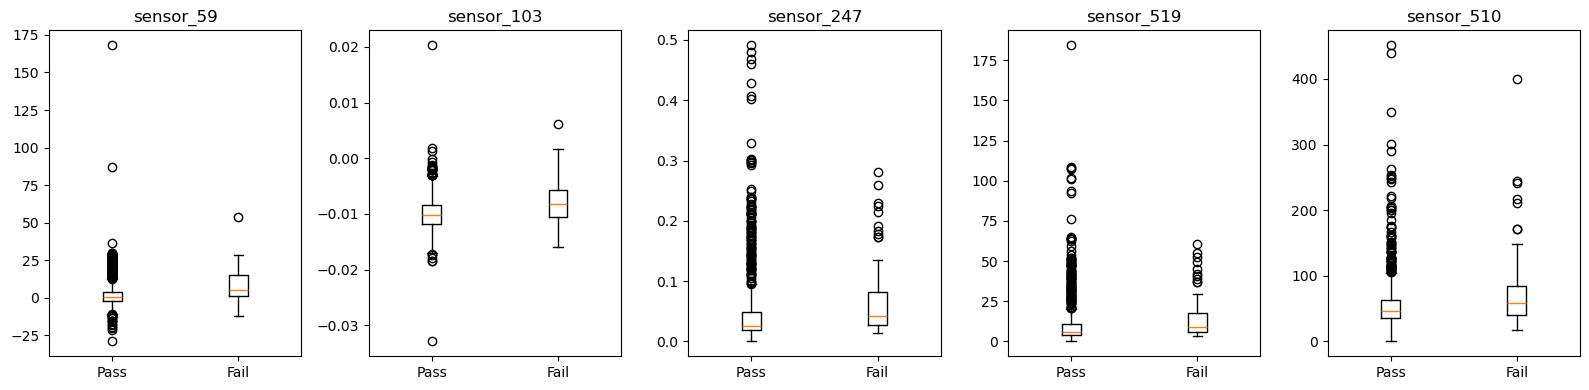

In [4]:
top = res.head(5)["sensor"]
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, s in zip(axes, top):
    data = [df.loc[~df["fail"], s].dropna(), df.loc[df["fail"], s].dropna()]
    ax.boxplot(data, tick_labels=["Pass", "Fail"])
    ax.set_title(s)
plt.tight_layout()
plt.savefig("../results/top_sensors_boxplots.png", dpi=150)
plt.show()

## Results: sensors associated with failures

- Compared each of the 446 sensors between passed and failed runs using the Mann–Whitney U test, with Benjamini–Hochberg correction for multiple testing.
- **20 sensors** differ significantly (q < 0.05).
- Most top sensors read **higher** in failed runs; sensor_28 is the main exception, reading lower.
- Effect sizes are moderate (about 0.2–0.4) and the distributions overlap, so no single sensor explains failures on its own. This is consistent with failures arising from several small process shifts rather than one obvious fault.
- sensor_247 and sensor_519 share an identical 45.6% missing rate, suggesting they come from a measurement step applied to only some runs.
- Selected for control charting: **sensor_59, sensor_103, sensor_510, sensor_28** (strong effects with nearly complete data).